In [5]:
from pathlib import Path
import joblib

PROJECT_ROOT = Path.cwd().parent

model_path = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "tuned"
    / "xgboost_tuned_model.pkl"
)

print("Project root:", PROJECT_ROOT)
print("Model exists:", model_path.exists())

model = joblib.load(model_path)

print("\nModel type:", type(model))
print("Pipeline steps:", model.named_steps.keys())

Project root: d:\MLProjects\Telecom Churn Prediction
Model exists: True

Model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'classifier'])


In [6]:
preprocessor = model.named_steps["preprocessor"]

print(type(preprocessor))
print(preprocessor.transformers_)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
[('numerical', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), BoxList(['SeniorCitizen', 'tenure', 'MonthlyCharges'])), ('categorical', Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))]), ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges'])]


In [7]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("\nFirst 20 feature names:")

for feature in feature_names[:20]:
    print(feature)

Total transformed features: 4311

First 20 feature names:
numerical__SeniorCitizen
numerical__tenure
numerical__MonthlyCharges
categorical__gender_Female
categorical__gender_Male
categorical__Partner_No
categorical__Partner_Yes
categorical__Dependents_No
categorical__Dependents_Yes
categorical__PhoneService_No
categorical__PhoneService_Yes
categorical__MultipleLines_No
categorical__MultipleLines_No phone service
categorical__MultipleLines_Yes
categorical__InternetService_DSL
categorical__InternetService_Fiber optic
categorical__InternetService_No
categorical__OnlineSecurity_No
categorical__OnlineSecurity_No internet service
categorical__OnlineSecurity_Yes


In [8]:
classifier = model.named_steps["classifier"]

print("Features from preprocessor:", len(feature_names))
print("Features used by XGBoost:", classifier.n_features_in_)

Features from preprocessor: 4311
Features used by XGBoost: 4311


In [9]:
classifier.feature_importances_

array([0.00450152, 0.02125457, 0.00976088, ..., 0.        , 0.        ,
       0.        ], shape=(4311,), dtype=float32)

In [10]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": classifier.feature_importances_
})

# Sort by importance in descending order
feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

print(feature_importance.head(20))

                                            feature  importance
0              categorical__Contract_Month-to-month    0.388742
1                    categorical__OnlineSecurity_No    0.115481
2                       categorical__TechSupport_No    0.100834
3          categorical__InternetService_Fiber optic    0.066992
4                    categorical__Contract_Two year    0.038332
5                   categorical__InternetService_No    0.026092
6       categorical__PaymentMethod_Electronic check    0.025145
7     categorical__OnlineBackup_No internet service    0.022018
8                                 numerical__tenure    0.021255
9   categorical__OnlineSecurity_No internet service    0.018021
10                   categorical__Contract_One year    0.017523
11                     categorical__StreamingTV_Yes    0.014472
12                     categorical__OnlineBackup_No    0.011491
13                 categorical__StreamingMovies_Yes    0.011381
14                 categorical__Paperles

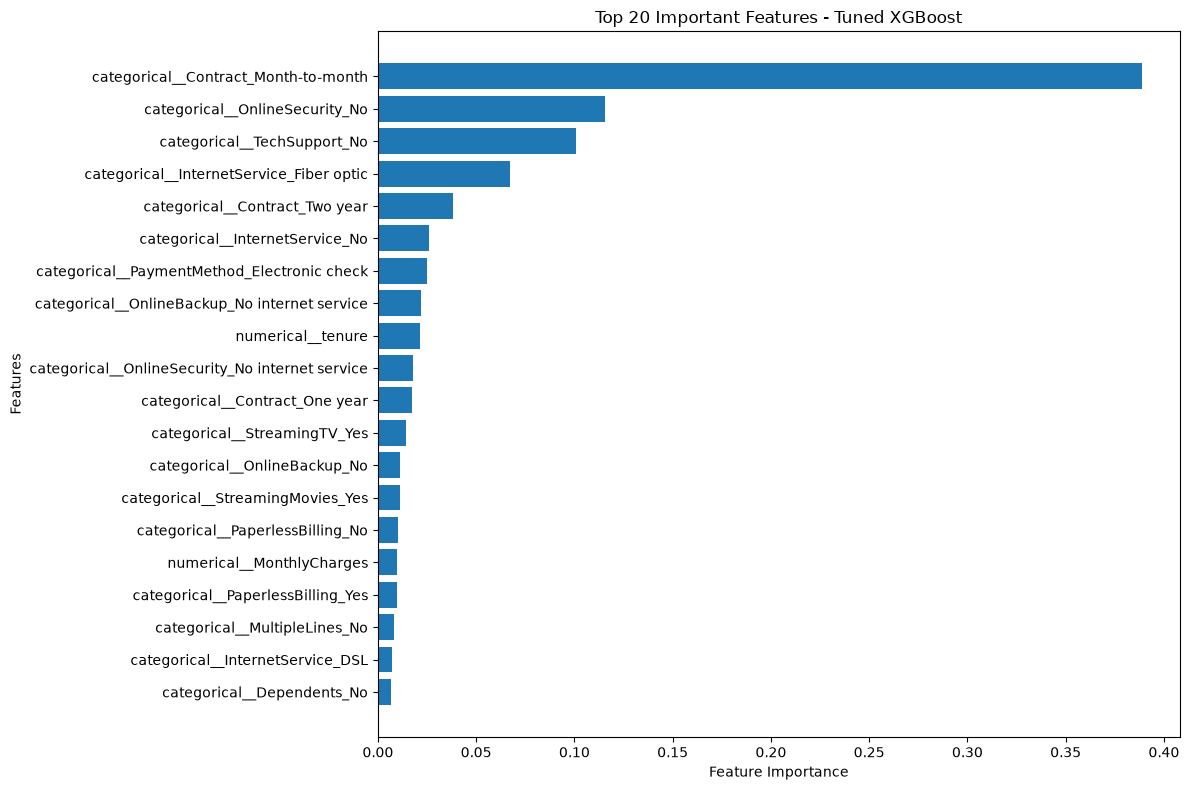

In [11]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(20).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 Important Features - Tuned XGBoost")

plt.tight_layout()
plt.show()

In [12]:
# Extract original feature names from transformed feature names
feature_importance["original_feature"] = (
    feature_importance["feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numerical__", "", regex=False)
)

# Aggregate importance by original feature
original_feature_importance = (
    feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(original_feature_importance.head(20))

                      original_feature  importance
0              Contract_Month-to-month    0.388742
1                    OnlineSecurity_No    0.115481
2                       TechSupport_No    0.100834
3          InternetService_Fiber optic    0.066992
4                    Contract_Two year    0.038332
5                   InternetService_No    0.026092
6       PaymentMethod_Electronic check    0.025145
7     OnlineBackup_No internet service    0.022018
8                               tenure    0.021255
9   OnlineSecurity_No internet service    0.018021
10                   Contract_One year    0.017523
11                     StreamingTV_Yes    0.014472
12                     OnlineBackup_No    0.011491
13                 StreamingMovies_Yes    0.011381
14                 PaperlessBilling_No    0.010028
15                      MonthlyCharges    0.009761
16                PaperlessBilling_Yes    0.009667
17                    MultipleLines_No    0.007983
18                 InternetServ

In [15]:
# Identify numerical and categorical original features
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "TotalCharges"
]

# Map transformed features to their original feature names
def get_original_feature(feature):
    feature = feature.replace("categorical__", "")
    feature = feature.replace("numerical__", "")

    if feature.startswith("num__"):
        feature = feature.replace("num__", "", 1)

    if feature.startswith("cat__"):
        feature = feature.replace("cat__", "", 1)

    for col in numerical_features + categorical_features:
        if feature == col or feature.startswith(col + "_"):
            return col

    return feature

feature_importance["original_feature"] = (
    feature_importance["feature"].apply(get_original_feature)
)

# Aggregate importance
original_feature_importance = (
    feature_importance
    .groupby("original_feature")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(original_feature_importance)

    original_feature  importance
0           Contract    0.444597
1     OnlineSecurity    0.137426
2        TechSupport    0.105714
3    InternetService    0.100362
4       OnlineBackup    0.038971
5      PaymentMethod    0.035544
6             tenure    0.021255
7   PaperlessBilling    0.019695
8        StreamingTV    0.016921
9      MultipleLines    0.014755
10   StreamingMovies    0.014054
11        Dependents    0.013550
12    MonthlyCharges    0.009761
13      PhoneService    0.008705
14            gender    0.005605
15           Partner    0.004872
16     SeniorCitizen    0.004502
17  DeviceProtection    0.003711
18      TotalCharges    0.000000


In [16]:
import pandas as pd

validation_path = (
    PROJECT_ROOT
    / "data"
    / "featured"
    / "validation_featured.csv"
)

validation_df = pd.read_csv(validation_path)

# Separate input features and target
X_validation = validation_df.drop(
    columns=["Churn", "customerID"]
)

# Select a representative sample
X_sample = X_validation.sample(
    n=200,
    random_state=42
)

# Transform using the fitted preprocessor
X_transformed = preprocessor.transform(X_sample)

print("Original shape:", X_sample.shape)
print("Transformed shape:", X_transformed.shape)

Original shape: (200, 19)
Transformed shape: (200, 4311)


In [18]:
import shap

# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(classifier)

# Calculate SHAP values
shap_values = explainer.shap_values(X_transformed)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (200, 4311)


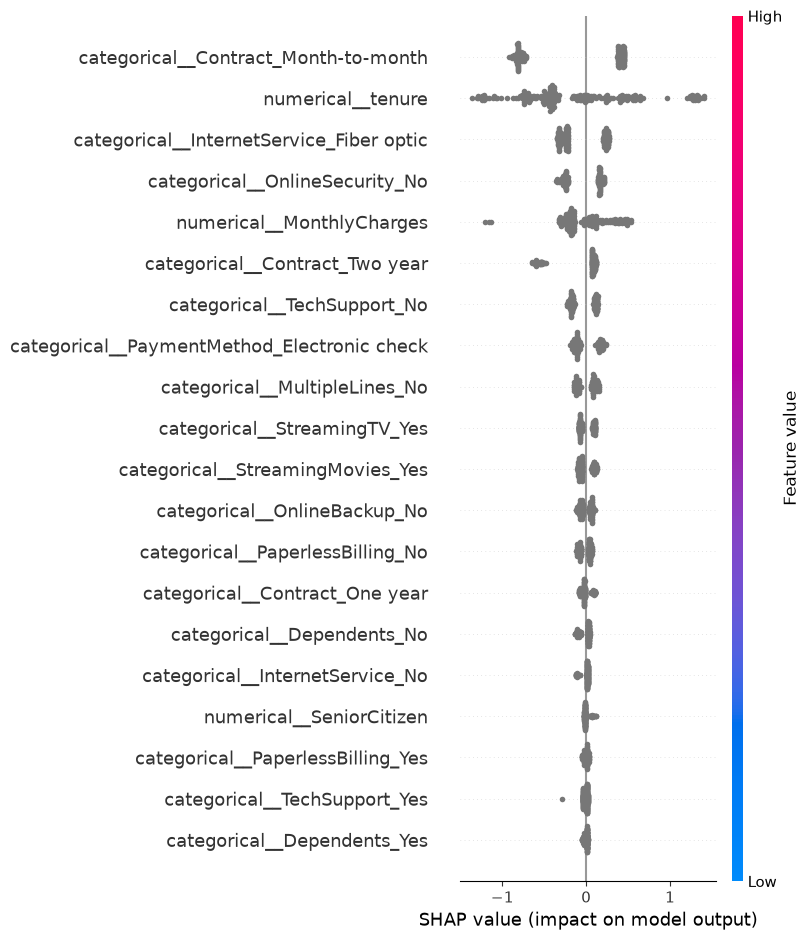

In [19]:
# SHAP global summary plot
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    max_display=20
)

In [20]:
# Select the first customer from our validation sample
customer_index = 0

customer = X_sample.iloc[[customer_index]]

print(customer.T)

                                     1090
gender                             Female
SeniorCitizen                           0
Partner                                No
Dependents                             No
tenure                                 50
PhoneService                           No
MultipleLines            No phone service
InternetService                       DSL
OnlineSecurity                         No
OnlineBackup                          Yes
DeviceProtection                      Yes
TechSupport                           Yes
StreamingTV                            No
StreamingMovies                        No
Contract                         Two year
PaperlessBilling                       No
PaymentMethod     Credit card (automatic)
MonthlyCharges                       39.7
TotalCharges                      1932.75


In [21]:
# Transform the selected customer's data
customer_transformed = preprocessor.transform(customer)

# Calculate SHAP values for this customer
customer_shap_values = explainer.shap_values(
    customer_transformed
)

print("SHAP shape:", customer_shap_values.shape)

SHAP shape: (1, 4311)


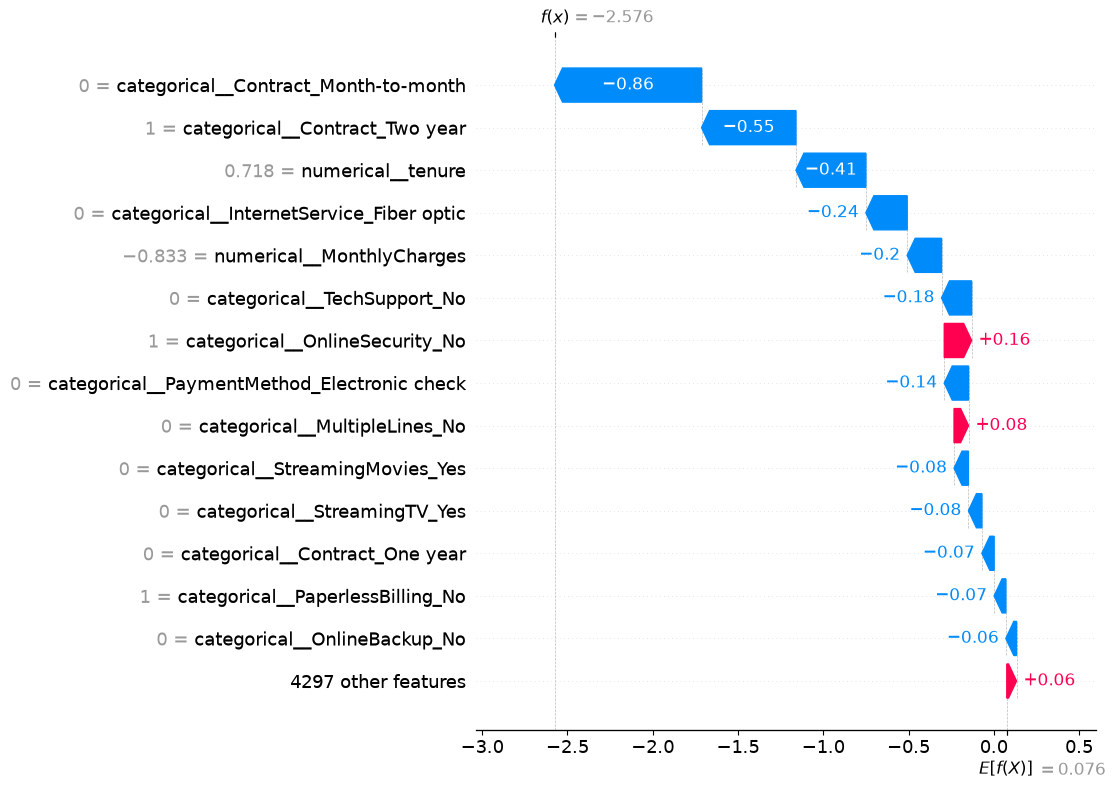

In [26]:
shap.waterfall_plot(
    shap.Explanation(
        values=customer_shap_values[0],
        base_values=explainer.expected_value,
        data=customer_transformed.toarray()[0]
            if hasattr(customer_transformed, "toarray")
            else customer_transformed[0],
        feature_names=feature_names
    ),
    max_display=15
)

In [24]:
print(classifier.predict(customer_transformed))

[0]


In [25]:
classifier.predict_proba(customer_transformed)

array([[0.9293066, 0.0706934]], dtype=float32)

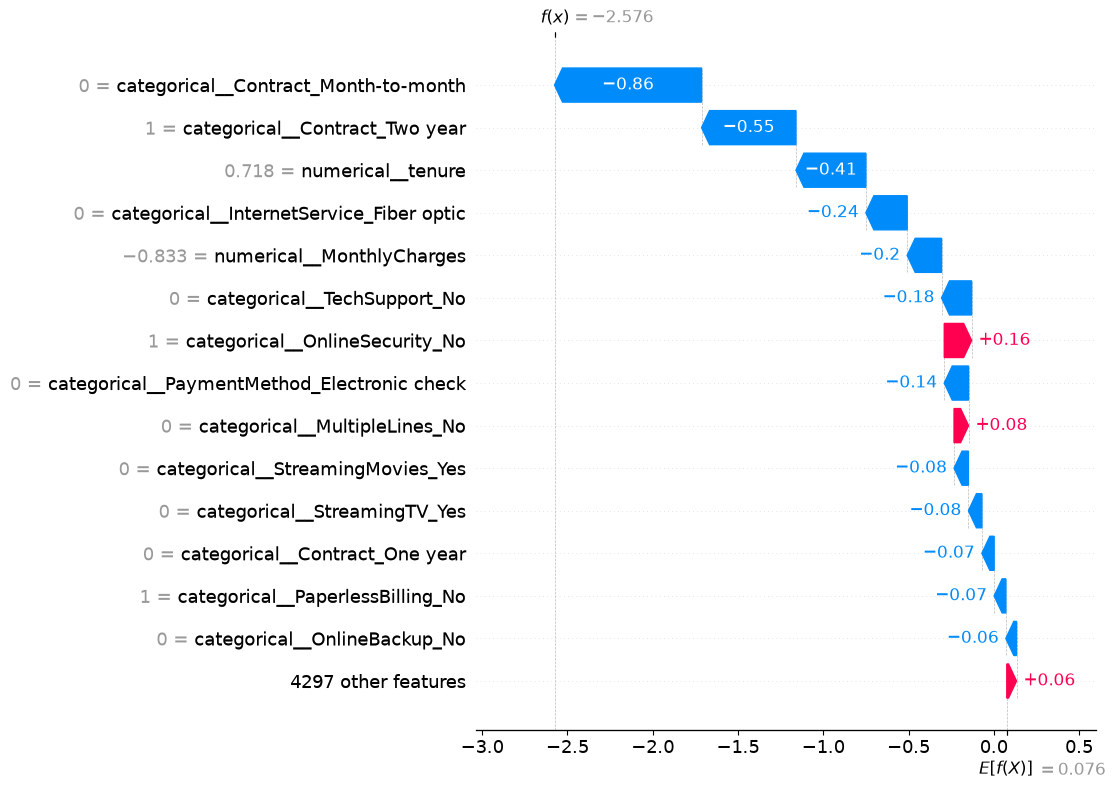

In [27]:
shap.waterfall_plot(
    shap.Explanation(
        values=customer_shap_values[0],
        base_values=explainer.expected_value,
        data=customer_transformed.toarray()[0]
            if hasattr(customer_transformed, "toarray")
            else customer_transformed[0],
        feature_names=feature_names
    ),
    max_display=15
)

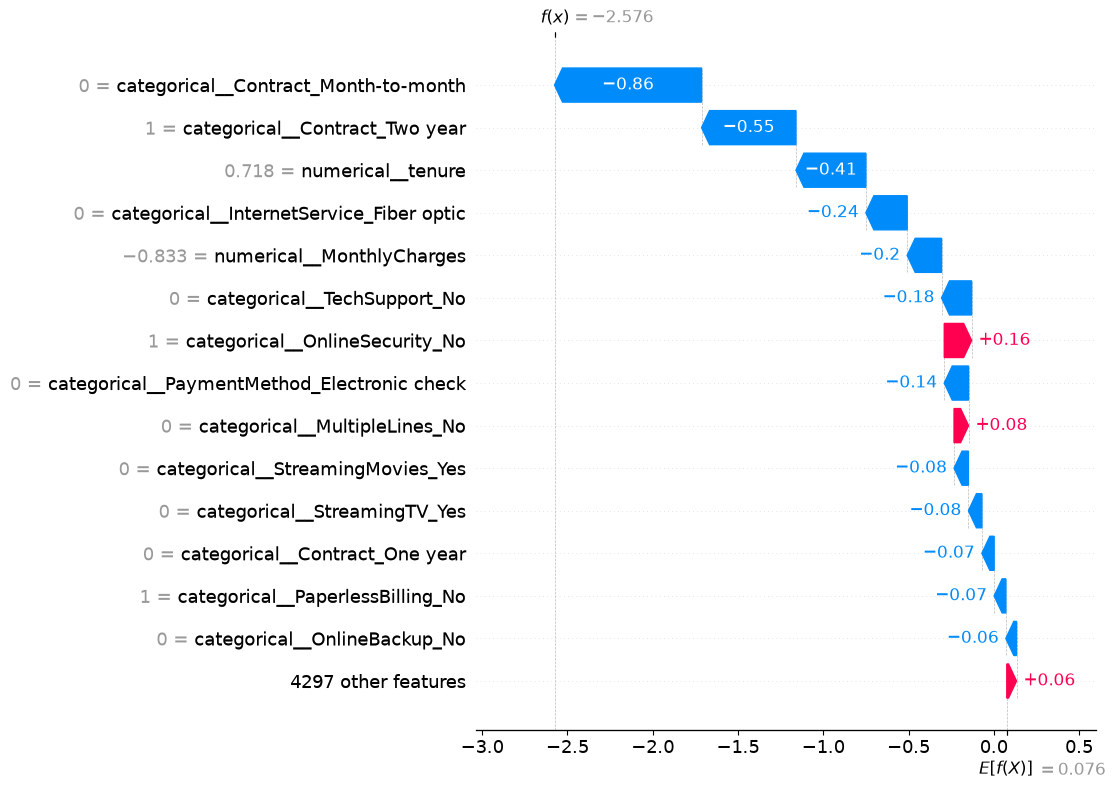

: 